Open Ended

In [13]:
#Import the Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


Dataset loaded successfully!
Dataset Shape: (1470, 35)

First 5 rows:
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   .

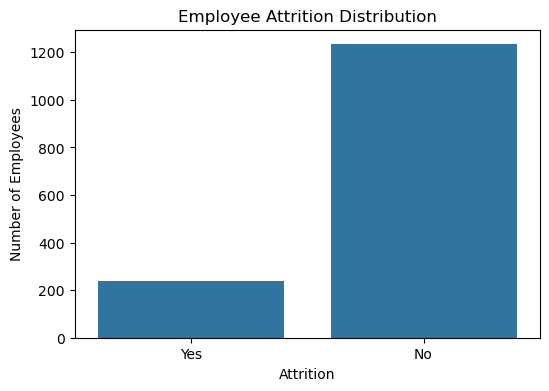

In [14]:
# 2. LOAD DATASET

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)


# 3. BASIC DATA EXPLORATION

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())


# 4. CHECK TARGET VARIABLE

print("\nAttrition Distribution:")
print(df["Attrition"].value_counts())

# Visualize Attrition
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()


# 5. REMOVE UNNECESSARY COLUMNS

# These columns contain the same value for every employee
# and therefore do not provide useful predictive information.

columns_to_drop = [
    "EmployeeCount",
    "EmployeeNumber",
    "Over18",
    "StandardHours"
]

df = df.drop(columns=columns_to_drop)


In [15]:
# 6. CONVERT TARGET VARIABLE

# Yes = 1
# No  = 0

df["Attrition"] = df["Attrition"].map({
    "Yes": 1,
    "No": 0
})

print("\nTarget variable after encoding:")
print(df["Attrition"].value_counts())


# 7. SEPARATE FEATURES AND TARGET

X = df.drop("Attrition", axis=1)
y = df["Attrition"]

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


# 8. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)



Target variable after encoding:
Attrition
0    1233
1     237
Name: count, dtype: int64

Features Shape: (1470, 30)
Target Shape: (1470,)

Numerical Features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical Features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [25]:

# 9. TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)



Training Data: (1176, 30)
Testing Data: (294, 30)


In [17]:


# 10. DATA PREPROCESSING

# Numerical columns:
# We use StandardScaler to normalize numerical data.

# Categorical columns:
# We use OneHotEncoder to convert categorical data into numerical values.

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)


# 11. CREATE MACHINE LEARNING MODELS

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)


decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=5,
                random_state=42
            )
        )
    ]
)


random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                random_state=42
            )
        )
    ]
)



In [18]:

# 12. TRAIN LOGISTIC REGRESSION

print("\nTraining Logistic Regression...")

logistic_model.fit(
    X_train,
    y_train
)

logistic_predictions = logistic_model.predict(X_test)


# 13. TRAIN DECISION TREE

print("Training Decision Tree...")

decision_tree_model.fit(
    X_train,
    y_train
)

decision_tree_predictions = decision_tree_model.predict(X_test)


# 14. TRAIN RANDOM FOREST

print("Training Random Forest...")

random_forest_model.fit(
    X_train,
    y_train
)

random_forest_predictions = random_forest_model.predict(X_test)



Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


In [19]:
# 15. EVALUATION FUNCTION

def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    print("\n======================================")
    print(model_name)
    print("======================================")

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=["Stayed", "Left"],
            zero_division=0
        )
    )

    return accuracy, precision, recall, f1



Logistic Regression
Accuracy : 0.8639
Precision: 0.64
Recall   : 0.3404
F1 Score : 0.4444

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92       247
        Left       0.64      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.76      0.65      0.68       294
weighted avg       0.85      0.86      0.85       294


Decision Tree
Accuracy : 0.8333
Precision: 0.4444
Recall   : 0.1702
F1 Score : 0.2462

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.86      0.96      0.91       247
        Left       0.44      0.17      0.25        47

    accuracy                           0.83       294
   macro avg       0.65      0.56      0.58       294
weighted avg       0.79      0.83      0.80       294


Random Forest
Accuracy : 0.8367
Precision: 0.4545
Recall   : 0.1064
F1 Score : 0.1724

Classification Report:
         

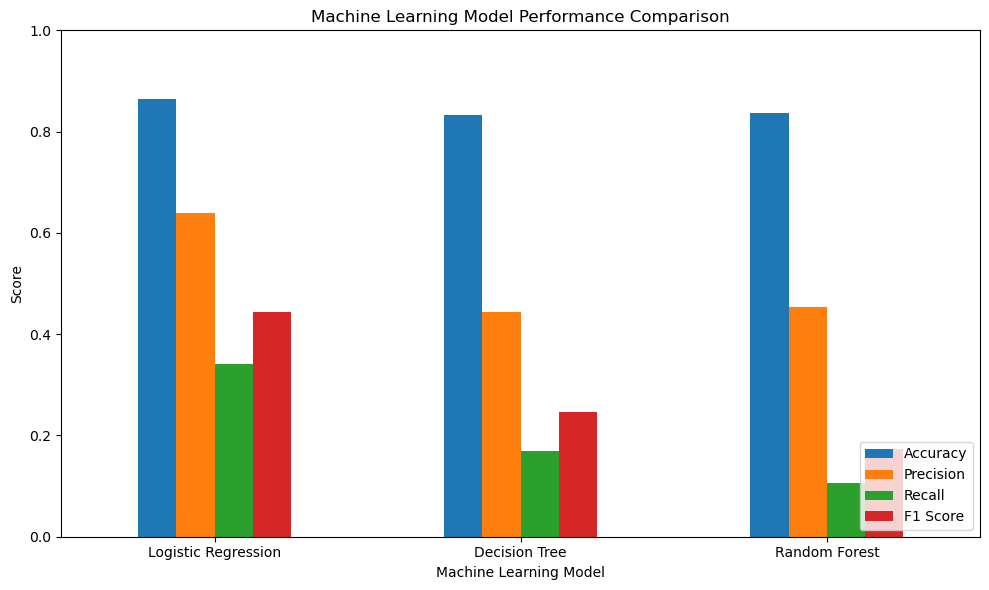

In [20]:
# 16. EVALUATE ALL MODELS

lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions
)

dt_results = evaluate_model(
    "Decision Tree",
    y_test,
    decision_tree_predictions
)

rf_results = evaluate_model(
    "Random Forest",
    y_test,
    random_forest_predictions
)



# 17. MODEL COMPARISON

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        lr_results[0],
        dt_results[0],
        rf_results[0]
    ],

    "Precision": [
        lr_results[1],
        dt_results[1],
        rf_results[1]
    ],

    "Recall": [
        lr_results[2],
        dt_results[2],
        rf_results[2]
    ],

    "F1 Score": [
        lr_results[3],
        dt_results[3],
        rf_results[3]
    ]
})

print("\n\nMODEL COMPARISON")
print("==============================")
print(results.round(4))

# 18. VISUALIZE MODEL COMPARISON

results_plot = results.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()



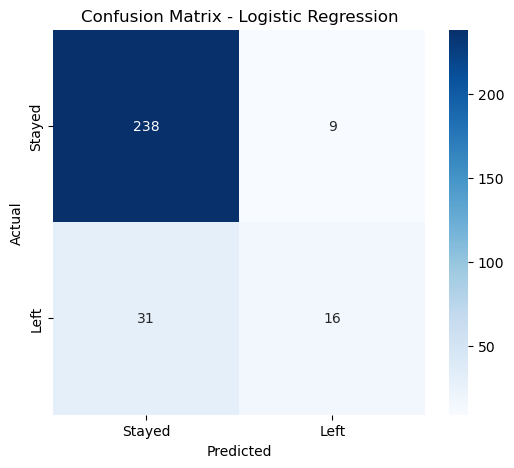

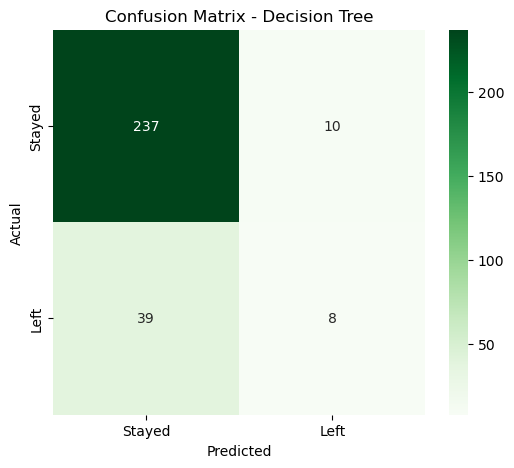

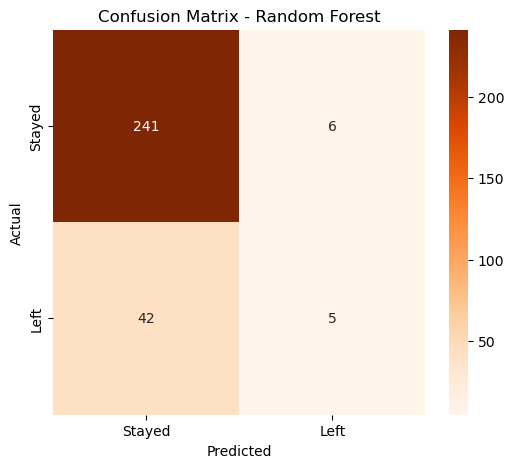

In [21]:

# 19. CONFUSION MATRIX - LOGISTIC REGRESSION

cm_lr = confusion_matrix(
    y_test,
    logistic_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# 20. CONFUSION MATRIX - DECISION TREE

cm_dt = confusion_matrix(
    y_test,
    decision_tree_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# 21. CONFUSION MATRIX - RANDOM FOREST

cm_rf = confusion_matrix(
    y_test,
    random_forest_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Stayed", "Left"],
    yticklabels=["Stayed", "Left"]
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()





Top 15 Important Features:
                     Feature  Importance
          num__MonthlyIncome    0.077683
                    num__Age    0.068484
      num__TotalWorkingYears    0.056835
              num__DailyRate    0.053913
            num__MonthlyRate    0.049557
         num__YearsAtCompany    0.047002
       num__DistanceFromHome    0.044746
             num__HourlyRate    0.044201
           cat__OverTime_Yes    0.039507
   num__YearsWithCurrManager    0.037753
     num__NumCompaniesWorked    0.033964
      num__PercentSalaryHike    0.032459
num__EnvironmentSatisfaction    0.028183
     num__YearsInCurrentRole    0.026129
       num__StockOptionLevel    0.024969


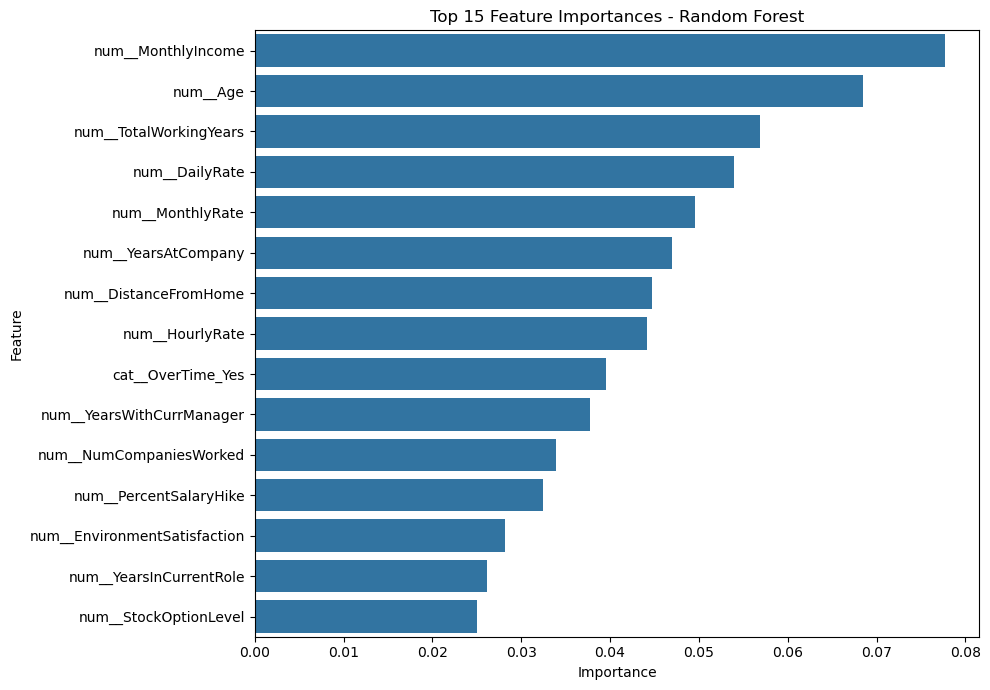

In [22]:
# 22. RANDOM FOREST FEATURE IMPORTANCE

# Get the fitted preprocessing step
fitted_preprocessor = random_forest_model.named_steps[
    "preprocessor"
]

# Get the fitted Random Forest
rf_classifier = random_forest_model.named_steps[
    "classifier"
]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance
importance = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)


# 23. DISPLAY TOP 15 IMPORTANT FEATURES

print("\nTop 15 Important Features:")
print(
    feature_importance.head(15).to_string(
        index=False
    )
)


# 24. FEATURE IMPORTANCE VISUALIZATION

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Feature Importances - Random Forest"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()




In [23]:
# 25. FIND BEST MODEL

best_model = results.loc[
    results["F1 Score"].idxmax()
]

print("\n======================================")
print("BEST MODEL")
print("======================================")

print(
    "Model:",
    best_model["Model"]
)

print(
    "F1 Score:",
    round(best_model["F1 Score"], 4)
)

print(
    "Accuracy:",
    round(best_model["Accuracy"], 4)
)

print(
    "Precision:",
    round(best_model["Precision"], 4)
)

print(
    "Recall:",
    round(best_model["Recall"], 4)
)





BEST MODEL
Model: Logistic Regression
F1 Score: 0.4444
Accuracy: 0.8639
Precision: 0.64
Recall: 0.3404


In [24]:

# 26. FINAL CONCLUSION


print("\n======================================")
print("CONCLUSION")
print("======================================")

print("""
The Employee Attrition Analyzer successfully predicts whether
an employee is likely to leave the company.

Three machine learning models were trained and compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The models were evaluated using Accuracy, Precision, Recall,
F1 Score, and Confusion Matrix.

Random Forest feature importance was also analyzed to identify
the employee characteristics that contribute most to attrition
prediction.

The model with the highest F1 Score is considered the best
performing model for this project.
""")


CONCLUSION

The Employee Attrition Analyzer successfully predicts whether
an employee is likely to leave the company.

Three machine learning models were trained and compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest

The models were evaluated using Accuracy, Precision, Recall,
F1 Score, and Confusion Matrix.

Random Forest feature importance was also analyzed to identify
the employee characteristics that contribute most to attrition
prediction.

The model with the highest F1 Score is considered the best
performing model for this project.

